# Real-data validation: LPRec3D ToMoBAR on I13 dataset 2

Reconstruct `i13_dataset2.npz` and compare numerical checks with the saved slice,
region of interest and line profile.

## Data and execution

Use `i13_dataset2.npz` from [Zenodo record 17252190](https://zenodo.org/records/17252190).
The repository downloader verifies the archive checksums.
Run from the repository root:

```bash
python .scripts/download_zenodo.py Zenodo
python -m pip install -e '.[validation]'
python -m pytest --nbmake --nbmake-timeout=1800 --overwrite docs/source/validation/reconstruction/direct/lprec3d_i13_dataset2.ipynb
```

Use an NVIDIA GPU with compatible CuPy and ToMoBAR installed, plus ASTRA for
ASTRA-based reconstruction. Run notebooks serially. Set `HTTOMOLIBGPU_DATA_DIR`
to use an archive stored elsewhere.

Documentation builds render saved outputs without running GPU computations.
Execute with `--overwrite` before building documentation to update the results.


In [1]:
import gc
import math
import pytest
import hashlib
import json
import os
import platform
from importlib.metadata import version
from pathlib import Path

import cupy as cp
import matplotlib.pyplot as plt
import numpy as np
from numpy.testing import assert_allclose

from httomolibgpu.prep.normalize import dark_flat_field_correction, minus_log
from httomolibgpu.recon.algorithm import LPRec3d_tomobar

# Locate the checkout from either the repository root or the notebook directory.
repo_root = next(
    (
        p
        for p in (Path.cwd(), *Path.cwd().parents)
        if (p / "pyproject.toml").is_file() and (p / "httomolibgpu").is_dir()
    ),
    None,
)
data_dir = os.environ.get("HTTOMOLIBGPU_DATA_DIR")
if data_dir is None:
    if repo_root is None:
        raise FileNotFoundError(
            "Set HTTOMOLIBGPU_DATA_DIR to the Zenodo archive directory"
        )
    data_dir = repo_root / "Zenodo"
data_path = Path(data_dir).expanduser() / "i13_dataset2.npz"
if not data_path.is_file():
    raise FileNotFoundError(
        f"Missing {data_path}; run .scripts/download_zenodo.py first"
    )

checksum = hashlib.sha256()
with data_path.open("rb") as stream:
    for chunk in iter(lambda: stream.read(1024 * 1024), b""):
        checksum.update(chunk)
props = cp.cuda.runtime.getDeviceProperties(cp.cuda.Device().id)
provenance = {
    "dataset": data_path.name,
    "zenodo_record": "17252190",
    "sha256": checksum.hexdigest(),
    "python": platform.python_version(),
    "packages": {
        name: version(name)
        for name in ("httomolibgpu", "tomobar", "astra-toolbox", "numpy")
    },
    "cupy": cp.__version__,
    "cuda_runtime": cp.cuda.runtime.runtimeGetVersion(),
    "cuda_driver": cp.cuda.runtime.driverGetVersion(),
    "gpu": (
        props["name"].decode() if isinstance(props["name"], bytes) else props["name"]
    ),
}
print(json.dumps(provenance, indent=2))

{
  "dataset": "i13_dataset2.npz",
  "zenodo_record": "17252190",
  "sha256": "11281ab163dd105ae5e550a411a5310d4156852a377eb058e66a765c68748461",
  "python": "3.14.7",
  "packages": {
    "httomolibgpu": "6.0.1.post16+git.bbaa03d2.dirty",
    "tomobar": "2026.3.1.0",
    "astra-toolbox": "2.5.0",
    "numpy": "2.4.6"
  },
  "cupy": "14.2.0",
  "cuda_runtime": 13020,
  "cuda_driver": 13020,
  "gpu": "NVIDIA GeForce RTX 4060"
}


## Preprocessing

Input axes are `(angle, detector row, detector column)`.
Apply default dark/flat correction and `minus_log`. Use all ten detector rows
and all angles in radians, with centre 1286.25 pixels. No stitching is applied.


Reconstruction input: (2501, 10, 2560)


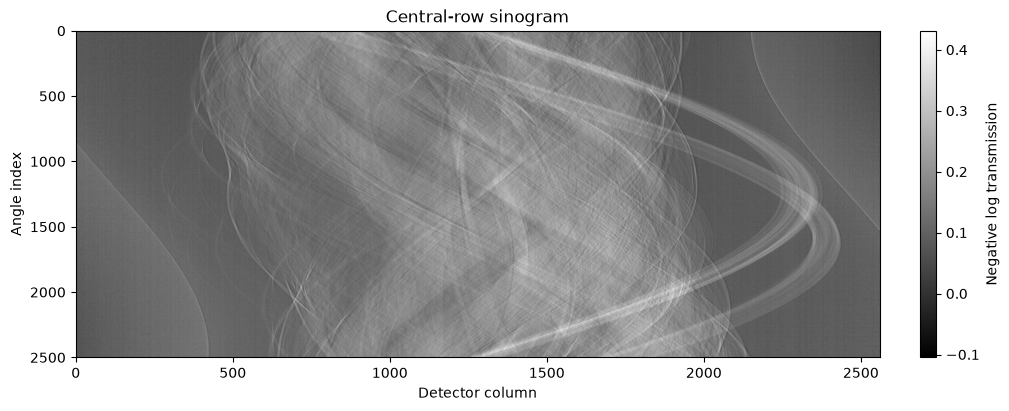

In [2]:
with np.load(data_path) as archive:
    projdata = cp.asarray(archive["projdata"])
    flats = cp.asarray(archive["flats"])
    darks = cp.asarray(archive["darks"])
    angles = archive["angles"].copy()
data_normalised = minus_log(dark_flat_field_correction(projdata, flats, darks))
del projdata, flats, darks
gc.collect()
cp.get_default_memory_pool().free_all_blocks()
assert bool(cp.isfinite(data_normalised).all())
reconstruction_input = data_normalised
del data_normalised
recon_angles = np.deg2rad(angles)
assert reconstruction_input.shape[0] == len(recon_angles)
assert bool(cp.isfinite(reconstruction_input).all())
print("Reconstruction input:", reconstruction_input.shape)
fig, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)
im = ax.imshow(
    reconstruction_input[:, reconstruction_input.shape[1] // 2, :].get(),
    cmap="gray",
    aspect="auto",
)
ax.set(title="Central-row sinogram", xlabel="Detector column", ylabel="Angle index")
fig.colorbar(im, ax=ax, label="Negative log transmission")
plt.show()
plt.close(fig)

## Reconstruction and regression assertions

Use the Shepp filter, response multiplier 1.0 and no detector padding.
Quantitative scaling (`legacy_scaling=False`) is used; reference values
are specific to this scaling and detector-row selection.
Output axes are `(Y, detector row, X)`. Numerical assertions run after plotting.


In [3]:
parameters = {
    "center": 1286.25,
    "detector_pad": False,
    "filter_type": "shepp",
    "filter_freq_cutoff": 1.0,
    "recon_mask_radius": 2.0,
    "legacy_scaling": False,
}
print("Reconstruction parameters:", parameters)
recon_gpu = LPRec3d_tomobar(reconstruction_input, recon_angles, **parameters)
assert isinstance(recon_gpu, cp.ndarray)
assert recon_gpu.flags.c_contiguous
assert recon_gpu.dtype == cp.float32
assert recon_gpu.shape == (2560, 10, 2560)
assert bool(cp.isfinite(recon_gpu).all())
recon_data = cp.asnumpy(recon_gpu)
del recon_gpu, reconstruction_input
gc.collect()
cp.get_default_memory_pool().free_all_blocks()
observed_mean = float(recon_data.mean(dtype=np.float64))
observed_max = float(recon_data.max())
observed_min = float(recon_data.min())
print(
    json.dumps(
        {
            "shape": list(recon_data.shape),
            "dtype": str(recon_data.dtype),
            "mean": observed_mean,
            "maximum": observed_max,
            "minimum": observed_min,
            "sum_float64": float(recon_data.sum(dtype=np.float64)),
        },
        indent=2,
    )
)
print("All structural validation checks passed.")

Reconstruction parameters: {'center': 1286.25, 'detector_pad': False, 'filter_type': 'shepp', 'filter_freq_cutoff': 1.0, 'recon_mask_radius': 2.0, 'legacy_scaling': False}


{
  "shape": [
    2560,
    10,
    2560
  ],
  "dtype": "float32",
  "mean": 2.0664218647523027e-05,
  "maximum": 0.004140364937484264,
  "minimum": -0.0032930164597928524,
  "sum_float64": 1354.250233284069
}
All structural validation checks passed.


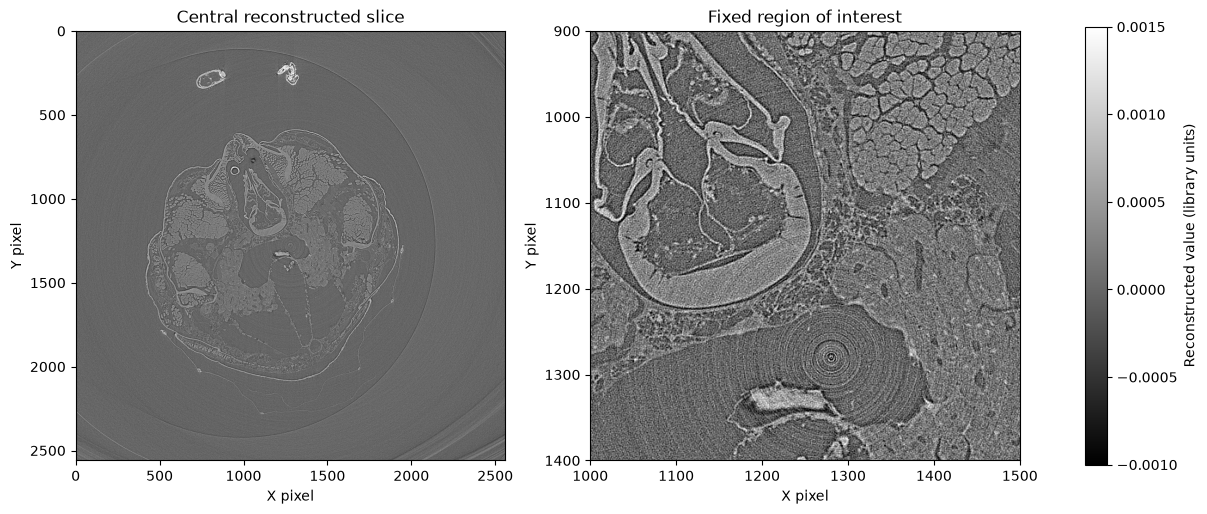

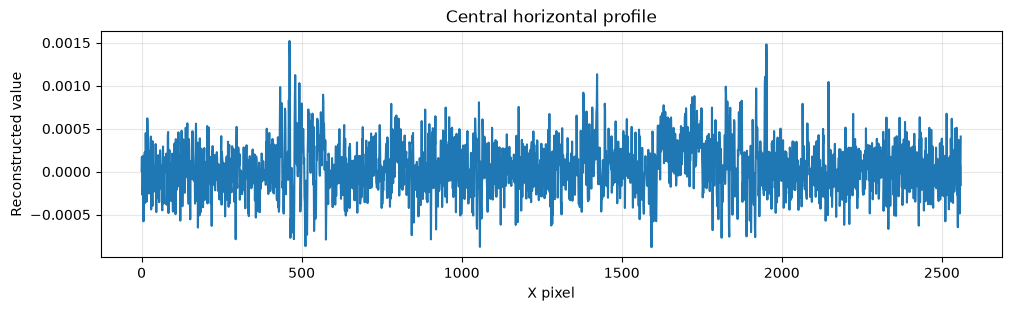

In [4]:
image = recon_data[:, recon_data.shape[1] // 2, :]
fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
limits = {"vmin": -0.001, "vmax": 0.0015, "cmap": "gray"}
im = axes[0].imshow(image, **limits)
axes[0].set(title="Central reconstructed slice", xlabel="X pixel", ylabel="Y pixel")
axes[1].imshow(image[900:1400, 1000:1500], extent=(1000, 1500, 1400, 900), **limits)
axes[1].set(title="Fixed region of interest", xlabel="X pixel", ylabel="Y pixel")
fig.colorbar(im, ax=axes, label="Reconstructed value (library units)")
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(10, 3), constrained_layout=True)
ax.plot(image[image.shape[0] // 2, :])
ax.set(
    title="Central horizontal profile", xlabel="X pixel", ylabel="Reconstructed value"
)
ax.grid(alpha=0.3)
plt.show()
plt.close(fig)

In [5]:
# Quantitative baseline from the initial GPU reference run (see provenance).
expected_mean = 2.0664218647523027e-05
expected_max = 0.004140364937484264
expected_min = -0.0032930164597928524
assert_allclose(
    observed_mean, expected_mean, rtol=1e-3, atol=1e-8, err_msg="Mean changed"
)
assert_allclose(
    observed_max, expected_max, rtol=1e-3, atol=1e-8, err_msg="Maximum changed"
)
assert_allclose(
    observed_min, expected_min, rtol=1e-3, atol=1e-8, err_msg="Minimum changed"
)
print("Mean, maximum and minimum regression checks passed.")

del recon_data, image
gc.collect()
cp.get_default_memory_pool().free_all_blocks()
cp.get_default_pinned_memory_pool().free_all_blocks()

Mean, maximum and minimum regression checks passed.
